# EDA 2: Dataset SIMPLIcity untuk pipeline 224

Eksplorasi data untuk pipeline kelompok yang berlaku sekarang: `common/data_utils.py` (letterbox 224×224, padding rata-rata ImageNet RGB 124, 116, 104, data 0–255 masuk ke model). Notebook ini menggantikan EDA dari branch `prepo` yang sudah dihapus, yang masih memakai ukuran 256.

Gambar hasil letterbox diambil dari `simplicity_224.npz` (dataset Kaggle `yonobengkel12/simplicity-224-letterbox`), yang identik dengan keluaran `_letterbox()` di `data_utils.py`. Kalau npz tidak ditemukan dan TensorFlow tersedia, letterbox dihitung langsung dengan `_letterbox()`.

Notebook ini hanya membaca data dan tidak melatih model. Statistik split test dipakai sebatas deskripsi dataset (ukuran, kecerahan, foto mirip), bukan untuk memilih model atau parameter.

| Keluaran | Isi |
|---|---|
| `figures/01_distribusi_kelas.png` | Jumlah gambar per kelas dan split |
| `figures/02_orientasi_portrait.png` | Porsi gambar portrait per kelas |
| `figures/03_kecerahan_kontras.png` | Sebaran kecerahan dan kontras |
| `figures/04_gambar_ditandai.png` | Gambar yang tergolong gelap, terang, atau kontras rendah |
| `figures/05_kandidat_foto_mirip.png` | Pasangan foto mirip antar-split |
| `figures/06_letterbox_vs_pembanding.png` | Letterbox 224 dibandingkan stretch dan center crop |
| `figures/07_sampel_per_kelas_224.png` | Sampel train setelah letterbox |
| `eda_2.json` | Ringkasan angka, daftar gambar yang ditandai, dan pasangan foto mirip |

## 1. Setup

In [1]:
import hashlib
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

ROOT = Path.cwd().resolve()
while not (ROOT / 'common' / 'data_utils.py').exists():   # naik sampai root repo
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Root repo (berisi common/data_utils.py) tidak ditemukan.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from common import data_utils as du   # konstanta dan letterbox resmi kelompok

DATA_DIR = du.DATA_DIR
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
IMG_SIZE = du.IMG_SIZE[0]
PAD_RGB = du.PAD_COLOR
CLASSES = list(du.CLASS_NAMES)
SPLITS = list(du.SPLITS)
PER_CLASS = du.EXPECTED_PER_CLASS
RESAMPLE = Image.Resampling.BILINEAR
SEED = du.SEED

# Gaya grafik: latar terang, garis bantu tipis, satu warna tetap per split
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
SPLIT_COLOR = {'train': '#2a78d6', 'validation': '#eb6834', 'test': '#1baf7a'}
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': INK2, 'grid.color': GRID, 'grid.linewidth': 1,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.family': ['Segoe UI', 'DejaVu Sans'], 'font.size': 10,
    'figure.dpi': 72, 'savefig.dpi': 150, 'savefig.bbox': 'tight',   # tampilan notebook ringan; file di figures/ 150 dpi
})


def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print('disimpan:', (FIG_DIR / name).as_posix())


def suptitle(fig, text):
    fig.suptitle(text, x=0.01, ha='left', fontsize=11, fontweight='bold')


du.sidik_config()
print(f'Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | Pillow {Image.__version__}')
print('Folder data:', DATA_DIR.relative_to(ROOT).as_posix())
print(f'Ukuran {IMG_SIZE}x{IMG_SIZE}, padding RGB {PAD_RGB}')

Sidik data_utils.py: b3e0629783c5  (lengkap: b3e0629783c56e87dc773010969802b88aaa44e43bc811bba5a553ff7a9aee6e)
Python 3.14.5 | numpy 2.5.4 | pandas 3.1.1 | Pillow 13.0.0
Folder data: data
Ukuran 224x224, padding RGB (124, 116, 104)


## 2. Inventaris dan validasi

Label diambil dari nomor berkas (`label = nomor // 100`), karena folder data tidak dipisah per kelas. Semua pemeriksaan dikumpulkan di satu tabel, ditambah `du.verifikasi_data()` milik pipeline kelompok.

In [2]:
rows, problems = [], []
for split in SPLITS:
    for p in sorted((DATA_DIR / split).iterdir()):
        if not p.is_file():
            continue
        if not p.stem.isdigit():
            problems.append(f'{split}/{p.name}: nama berkas bukan nomor')
            continue
        try:
            with Image.open(p) as im:
                im.verify()                      # struktur berkas utuh
            with Image.open(p) as im:
                im.load()                        # seluruh piksel bisa dibaca
                width, height, mode = im.width, im.height, im.mode
        except Exception as e:
            problems.append(f'{split}/{p.name}: {e}')
            continue
        rows.append({'split': split, 'file': p.name, 'code': int(p.stem), 'width': width, 'height': height,
                     'mode': mode, 'md5': hashlib.md5(p.read_bytes()).hexdigest(), 'path': p})

df = pd.DataFrame(rows)
df['split'] = pd.Categorical(df['split'], categories=SPLITS, ordered=True)
df = df.sort_values(['split', 'code'], ignore_index=True)
df['label'] = df['code'] // 100
df['class'] = pd.Categorical(df['label'].map(dict(enumerate(CLASSES))), categories=CLASSES, ordered=True)
df['orientation'] = np.where(df['height'] > df['width'], 'portrait', 'landscape')

per_class = pd.crosstab(df['class'], df['split'])
per_class.columns = [str(c) for c in per_class.columns]

checks = []


def check(name, ok, detail):
    checks.append({'pemeriksaan': name, 'lolos': bool(ok), 'keterangan': detail})


split_counts = df['split'].astype(str).value_counts()
shortest = df[['width', 'height']].min(axis=1)
check('Berkas rusak atau nama tidak valid', not problems, f'{len(problems)} masalah' + (f': {problems[:3]}' if problems else ''))
check('Format berkas', set(df['file'].str.lower().str.rsplit('.', n=1).str[-1]) == {'jpg'}, 'semua .jpg')
check('Nomor berkas unik, 0–999', df['code'].is_unique and df['code'].between(0, 999).all(),
      f'{df["code"].min()} sampai {df["code"].max()}')
check('Jumlah per split', all(split_counts.get(s, 0) == n * 10 for s, n in PER_CLASS.items()),
      ', '.join(f'{s} {split_counts.get(s, 0)}' for s in SPLITS))
check('Stratified: 50/30/20 per kelas', (per_class[SPLITS].to_numpy() == np.array([PER_CLASS[s] for s in SPLITS])).all(),
      'semua kelas sama rata')
check('Aturan split dari dua digit terakhir', df.apply(lambda r: du.KODE_PER_SPLIT[r['split']][0] <= r['code'] % 100 <= du.KODE_PER_SPLIT[r['split']][1], axis=1).all(),
      'x00–x49 train, x50–x79 validation, x80–x99 test')
check('Tidak ada duplikat persis (md5)', df['md5'].is_unique, f'{df["md5"].duplicated().sum()} duplikat')
check(f'Sisi terpendek minimal {IMG_SIZE} px (tidak ada yang diperbesar)', (shortest >= IMG_SIZE).all(),
      f'sisi terpendek {shortest.min()} px')
check('Mode warna', True, ', '.join(f'{m}: {n}' for m, n in df['mode'].value_counts().items()))
try:
    du.verifikasi_data(cek_hash=False)
    check('du.verifikasi_data()', True, 'lolos (tanpa cek manifest)')
except ValueError as e:
    check('du.verifikasi_data()', False, str(e)[:120])

display(pd.DataFrame(checks).assign(lolos=lambda t: t['lolos'].map({True: '✔', False: '✘'})))
print('Total gambar:', len(df))

,pemeriksaan,lolos,keterangan
0,Berkas rusak atau nama tidak valid,✔,0 masalah
1,Format berkas,✔,semua .jpg
2,"Nomor berkas unik, 0–999",✔,0 sampai 999
3,Jumlah per split,✔,"train 500, validation 300, test 200"
4,Stratified: 50/30/20 per kelas,✔,semua kelas sama rata
5,Aturan split dari dua digit terakhir,✔,"x00–x49 train, x50–x79 validation, x80–x99 test"
6,Tidak ada duplikat persis (md5),✔,0 duplikat
7,Sisi terpendek minimal 224 px (tidak ada yang ...,✔,sisi terpendek 256 px
8,Mode warna,✔,RGB: 1000
9,du.verifikasi_data(),✔,lolos (tanpa cek manifest)


Total gambar: 1000


## 3. Distribusi kelas, ukuran, dan orientasi

,train,validation,test
class,,,
People,50,30,20
Beach,50,30,20
Building,50,30,20
Bus,50,30,20
Dinosaur,50,30,20
Elephant,50,30,20
Flower,50,30,20
Horse,50,30,20
Mountain,50,30,20


disimpan: figures/01_distribusi_kelas.png


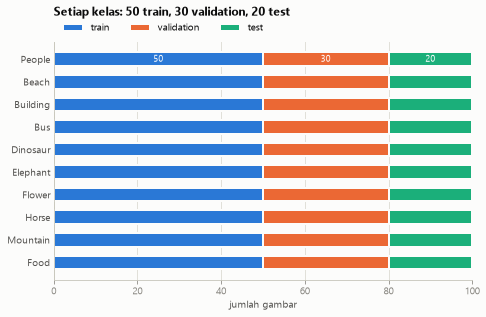

In [3]:
display(per_class)

fig, ax = plt.subplots(figsize=(7.5, 4.3))
left = np.zeros(len(CLASSES))
for split in SPLITS:
    vals = per_class[split].to_numpy()
    ax.barh(CLASSES, vals, left=left, height=0.6, color=SPLIT_COLOR[split], edgecolor=SURFACE, linewidth=2, label=split)
    ax.text(left[0] + vals[0] / 2, 0, str(vals[0]), ha='center', va='center', color='white', fontsize=9)
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('jumlah gambar')
ax.tick_params(axis='y', length=0)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_title('Setiap kelas: 50 train, 30 validation, 20 test', pad=26)
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0))
save(fig, '01_distribusi_kelas.png')
plt.show()

,width,height,jumlah,orientasi,persen
0,256,384,200,portrait,20.0
1,384,256,800,landscape,80.0


,portrait train (%),portrait validation (%),portrait test (%),portrait semua (%)
class,,,,
People,36,47,30,38
Beach,14,17,25,17
Building,28,27,35,29
Bus,0,0,10,2
Dinosaur,0,0,0,0
Elephant,12,10,30,15
Flower,0,17,15,8
Horse,8,40,20,20
Mountain,36,33,35,35


disimpan: figures/02_orientasi_portrait.png


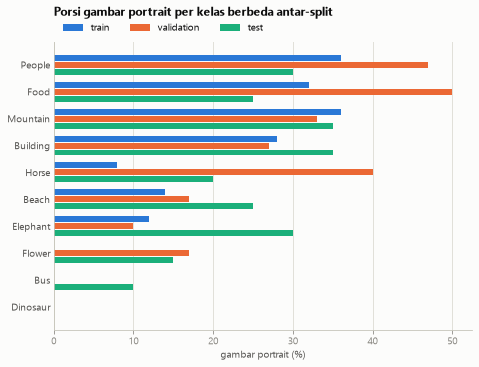

In [4]:
size_tab = df.groupby(['width', 'height']).size().rename('jumlah').reset_index()
size_tab['orientasi'] = np.where(size_tab['height'] > size_tab['width'], 'portrait', 'landscape')
size_tab['persen'] = (size_tab['jumlah'] / len(df) * 100).round(1)
display(size_tab)

portrait = pd.crosstab(df['class'], df['split'], values=(df['orientation'] == 'portrait'), aggfunc='mean') * 100
portrait.columns = [str(c) for c in portrait.columns]
portrait['semua'] = df.assign(p=df['orientation'] == 'portrait').groupby('class', observed=True)['p'].mean() * 100
portrait = portrait.round(0).astype(int)
display(portrait.rename(columns=lambda c: f'portrait {c} (%)'))

order = portrait.sort_values('semua', ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ys, h = np.arange(len(order)), 0.26
for k, split in enumerate(SPLITS):
    ax.barh(ys + (k - 1) * h, portrait.loc[order, split], height=h * 0.85, color=SPLIT_COLOR[split], label=split)
ax.set_yticks(ys, order)
ax.invert_yaxis()
ax.set_xlabel('gambar portrait (%)')
ax.tick_params(axis='y', length=0)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_title('Porsi gambar portrait per kelas berbeda antar-split', pad=26)
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0))
save(fig, '02_orientasi_portrait.png')
plt.show()

**Bacaan.** Hanya ada dua ukuran: 384×256 (landscape) dan 256×384 (portrait), dengan sisi terpendek 256, jadi resize ke 224 selalu memperkecil. Sekitar seperlima gambar berorientasi portrait, dan porsinya berbeda per kelas serta antar-split. Karena itu gambar tidak bisa langsung dipaksa persegi tanpa merusak proporsi (bagian 6). Dengan letterbox, orientasi tetap terlihat dari letak pita padding, jadi perbedaan porsi ini perlu diingat saat error analysis.

## 4. Kecerahan dan kontras

Kecerahan rata-rata dan kontras (simpangan baku kecerahan) per gambar, untuk menilai perlu tidaknya contrast enhancement.

,kecerahan rata-rata,kontras rata-rata
class,,
People,95.099998,55.900002
Beach,107.099998,43.599998
Building,98.699997,53.400002
Bus,92.699997,59.599998
Dinosaur,200.800003,50.900002
Elephant,129.000000,50.700001
Flower,57.799999,45.200001
Horse,92.500000,38.599998
Mountain,103.900002,54.599998


disimpan: figures/03_kecerahan_kontras.png


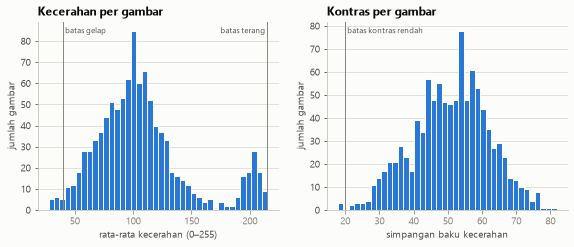

16 gambar ditandai; per kelas: {'Flower': 12, 'Building': 2, 'Dinosaur': 1, 'Beach': 1}


,split,file,class,lum_mean,lum_std,flag
0,train,234.jpg,Building,38.599998,28.500000,gelap
1,train,245.jpg,Building,33.000000,30.600000,gelap
2,train,439.jpg,Dinosaur,215.199997,34.799999,terang
3,train,616.jpg,Flower,34.500000,17.799999,"gelap, kontras rendah"
4,train,618.jpg,Flower,34.299999,25.100000,gelap
5,train,637.jpg,Flower,37.500000,28.200001,gelap
6,validation,161.jpg,Beach,110.599998,19.299999,kontras rendah
7,validation,657.jpg,Flower,35.099998,17.799999,"gelap, kontras rendah"
8,validation,659.jpg,Flower,29.700001,36.700001,gelap
9,validation,660.jpg,Flower,33.299999,47.000000,gelap


In [5]:
def luminance_stats(path):
    with Image.open(path) as im:
        g = np.asarray(im.convert('RGB').resize((128, 128), RESAMPLE).convert('L'), dtype=np.float32)
    return g.mean(), g.std()


df[['lum_mean', 'lum_std']] = [luminance_stats(p) for p in df['path']]
DARK, BRIGHT, LOW_CONTRAST = 40, 215, 20
df['flag'] = [', '.join(name for name, hit in (('gelap', m < DARK), ('terang', m > BRIGHT), ('kontras rendah', s < LOW_CONTRAST)) if hit)
              for m, s in zip(df['lum_mean'], df['lum_std'])]

display(df.groupby('class', observed=True)[['lum_mean', 'lum_std']].mean().round(1)
        .rename(columns={'lum_mean': 'kecerahan rata-rata', 'lum_std': 'kontras rata-rata'}))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
specs = ((axes[0], 'lum_mean', [(DARK, 'batas gelap'), (BRIGHT, 'batas terang')], 'rata-rata kecerahan (0–255)', 'Kecerahan per gambar'),
         (axes[1], 'lum_std', [(LOW_CONTRAST, 'batas kontras rendah')], 'simpangan baku kecerahan', 'Kontras per gambar'))
for ax, col, lines, xlabel, title in specs:
    ax.hist(df[col], bins=40, color=SPLIT_COLOR['train'], edgecolor=SURFACE, linewidth=1)
    top = ax.get_ylim()[1]
    mid = sum(ax.get_xlim()) / 2
    for x, name in lines:
        ax.axvline(x, color=MUTED, linewidth=1)
        right_side = x > mid                     # label garis kanan diletakkan di kiri garis supaya tidak keluar panel
        ax.text(x, top * 0.97, f'{name} ' if right_side else f' {name}', color=INK2, fontsize=8, va='top',
                ha='right' if right_side else 'left')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('jumlah gambar')
    ax.set_title(title)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
save(fig, '03_kecerahan_kontras.png')
plt.show()

flagged = df[df['flag'] != ''].reset_index(drop=True)
print(f'{len(flagged)} gambar ditandai; per kelas: {flagged["class"].astype(str).value_counts().to_dict()}')
display(flagged[['split', 'file', 'class', 'lum_mean', 'lum_std', 'flag']].round(1))

disimpan: figures/04_gambar_ditandai.png


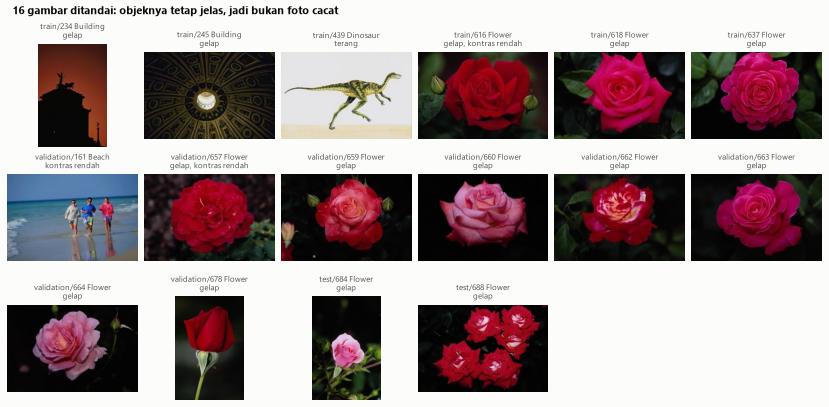

In [6]:
cols = 6
n_rows = max(1, math.ceil(len(flagged) / cols))
fig, axes = plt.subplots(n_rows, cols, figsize=(cols * 1.9, n_rows * 1.85), squeeze=False, layout='constrained')
for ax in axes.flat:
    ax.axis('off')
for ax, (_, r) in zip(axes.flat, flagged.iterrows()):
    with Image.open(r['path']) as im:
        im = im.convert('RGB')
        im.thumbnail((224, 224))
        ax.imshow(im)
    ax.set_title(f"{r['split']}/{r['code']} {r['class']}\n{r['flag']}", fontsize=7.5, color=INK2, loc='center', fontweight='normal')
suptitle(fig, f'{len(flagged)} gambar ditandai: objeknya tetap jelas, jadi bukan foto cacat')
save(fig, '04_gambar_ditandai.png')
plt.show()

**Bacaan.** Gambar yang tergolong gelap hampir semuanya mawar berlatar hitam (kelas Flower), ditambah beberapa foto Building seperti siluet di langit senja. Gambar terang berasal dari latar putih, misalnya Dinosaur. Objek di semua gambar ini tetap jelas. Gelap atau terangnya berasal dari gaya foto yang konsisten per kelas, bukan dari cacat foto.

Karena itu contrast enhancement seperti CLAHE tidak dipakai. CLAHE tidak mengubah urutan kecerahan antar-kelas, menguatkan noise di area gelap, dan menggeser warna. Ketahanan terhadap perbedaan cahaya diberikan lewat augmentation brightness dan contrast ±15% saat training (`du.get_augmentation()`).

## 5. Foto mirip antar-split

Foto dari sesi pemotretan yang sama bisa jatuh di train dan test sekaligus. Kalau begitu, akurasi test tampak lebih tinggi dari kemampuan model yang sebenarnya.

Caranya: setiap gambar diperkecil ke 32×32 RGB, lalu setiap pasangan dari split berbeda dibandingkan dengan mean squared error (MSE). Pasangan dengan MSE di bawah 0,01 dianggap kandidat, lalu diperiksa dengan mata. Kandidat **tidak dihapus**, karena split mengikuti modul 11. Temuannya dipakai untuk uji kepekaan saat evaluasi test.

In [7]:
NEAR_DUP_MSE = 0.01
thumbs = []
for p in df['path']:
    with Image.open(p) as im:
        thumbs.append(np.asarray(im.convert('RGB').resize((32, 32), RESAMPLE), dtype=np.float32).ravel() / 255)
thumbs = np.stack(thumbs)
sq = (thumbs ** 2).sum(1)
dist = (sq[:, None] + sq[None, :] - 2 * thumbs @ thumbs.T) / thumbs.shape[1]   # MSE setiap pasangan
ia, ib = np.triu_indices(len(df), 1)
split_arr = df['split'].astype(str).to_numpy()
keep = (split_arr[ia] != split_arr[ib]) & (dist[ia, ib] < NEAR_DUP_MSE)
pairs = pd.DataFrame({
    'a': [f"{split_arr[k]}/{df.at[k, 'code']}" for k in ia[keep]],
    'b': [f"{split_arr[k]}/{df.at[k, 'code']}" for k in ib[keep]],
    'kelas a': df['class'].astype(str).to_numpy()[ia[keep]],
    'kelas b': df['class'].astype(str).to_numpy()[ib[keep]],
    'mse': dist[ia[keep], ib[keep]],
    'ia': ia[keep], 'ib': ib[keep],
}).sort_values('mse', ignore_index=True)
touch_test = pairs['a'].str.startswith('test') | pairs['b'].str.startswith('test')
test_twins = sorted({int(n.split('/')[1]) for col in ('a', 'b') for n in pairs[col] if n.startswith('test/')})
display(pairs.drop(columns=['ia', 'ib']).round({'mse': 4}))
print(f'{len(pairs)} pasangan kandidat, {touch_test.sum()} melibatkan test; per kelas: {pairs["kelas a"].value_counts().to_dict()}')
print(f'Gambar test yang punya kembaran di split lain ({len(test_twins)}): {test_twins}')

,a,b,kelas a,kelas b,mse
0,validation/768,test/789,Horse,Horse,0.0023
1,validation/763,test/791,Horse,Horse,0.0056
2,train/718,test/795,Horse,Horse,0.0060
3,validation/770,test/791,Horse,Horse,0.0068
4,validation/769,test/786,Horse,Horse,0.0075
5,train/503,validation/567,Elephant,Elephant,0.0078
6,train/749,validation/766,Horse,Horse,0.0079
7,validation/760,test/789,Horse,Horse,0.0081
8,validation/774,test/796,Horse,Horse,0.0083
9,train/616,validation/657,Flower,Flower,0.0086


11 pasangan kandidat, 8 melibatkan test; per kelas: {'Horse': 9, 'Elephant': 1, 'Flower': 1}
Gambar test yang punya kembaran di split lain (6): [786, 787, 789, 791, 795, 796]


disimpan: figures/05_kandidat_foto_mirip.png


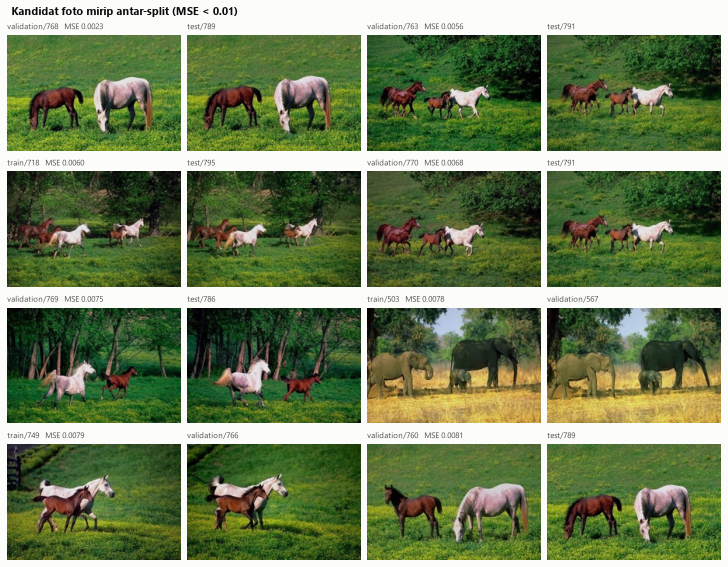

In [8]:
show = pairs.head(8)
if len(show):
    n_rows = math.ceil(len(show) / 2)
    fig, axes = plt.subplots(n_rows, 4, figsize=(10, 1.95 * n_rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for k, (_, r) in enumerate(show.iterrows()):
        for m, (idx, name) in enumerate(((r['ia'], r['a']), (r['ib'], r['b']))):
            ax = axes.flat[k * 2 + m]
            with Image.open(df.at[idx, 'path']) as im:
                im = im.convert('RGB')
                im.thumbnail((224, 224))
                ax.imshow(im)
            ax.set_title(name + (f"   MSE {r['mse']:.4f}" if m == 0 else ''), fontsize=8, color=INK2, loc='left', fontweight='normal')
    suptitle(fig, f'Kandidat foto mirip antar-split (MSE < {NEAR_DUP_MSE})')
    save(fig, '05_kandidat_foto_mirip.png')
    plt.show()

**Bacaan.** Hampir semua kandidat berasal dari kelas Horse dari sesi pemotretan yang sama: padang rumput dan kuda yang sama, diambil beberapa saat berselang. Akibatnya akurasi test kelas Horse kemungkinan terlalu optimistis. Uji kepekaan yang disarankan: hitung ulang akurasi test tanpa gambar test yang punya kembaran (daftarnya di atas dan di `eda_2.json`).

## 6. Resize: letterbox 224 dibandingkan stretch dan center crop

Pipeline kelompok memakai **letterbox**: sisi panjang diperkecil ke 224 dengan rasio tetap, lalu sisa kanvas diisi warna rata-rata ImageNet RGB (124, 116, 104). Gambar letterbox di bawah diambil dari npz, jadi persis sama dengan yang diterima model.

In [9]:
npz_path = du._cari_npz()
if npz_path is not None:
    isi = du._muat_npz(npz_path)          # checksum isi dicek di sini
    X = {s: isi[f'x_{s}'] for s in SPLITS}
    IDS = {s: isi[f'id_{s}'] for s in SPLITS}
    print('Sumber letterbox:', npz_path.name, '(checksum cocok)')
else:                                     # cadangan: hitung dengan _letterbox() (butuh TensorFlow)
    X, IDS = {}, {}
    for s in SPLITS:
        paths = du._daftar_gambar(s)
        X[s] = np.stack([du._letterbox(str(p)).numpy() for p in paths])
        IDS[s] = np.array([int(p.stem) for p in paths])
    print('Sumber letterbox: du._letterbox() dari JPEG')

for s in SPLITS:
    assert (IDS[s] == df.loc[df['split'] == s, 'code'].to_numpy()).all(), s
pad_mask = {s: (X[s] == np.array(PAD_RGB, np.uint8)).all(axis=-1) for s in SPLITS}
pad_share = np.mean(np.concatenate([m.mean(axis=(1, 2)) for m in pad_mask.values()]))
land = X['train'][df.loc[df['split'] == 'train', 'orientation'].to_numpy() == 'landscape'][0]
rows_isi = int((~(land == np.array(PAD_RGB, np.uint8)).all(axis=-1)).any(axis=1).sum())
print(f'Bentuk: {X["train"].shape[1:]} uint8 | landscape 384x256 menjadi 224x{rows_isi} di tengah kanvas')
print(f'Porsi kanvas berwarna padding rata-rata: {pad_share:.1%}')
print(f'Center crop membuang {1 - 256 / 384:.1%} sisi panjang gambar (sepertiga lebar foto landscape)')

Sumber letterbox: simplicity_224.npz (checksum cocok)


Bentuk: (224, 224, 3) uint8 | landscape 384x256 menjadi 224x149 di tengah kanvas
Porsi kanvas berwarna padding rata-rata: 33.5%
Center crop membuang 33.3% sisi panjang gambar (sepertiga lebar foto landscape)


disimpan: figures/06_letterbox_vs_pembanding.png


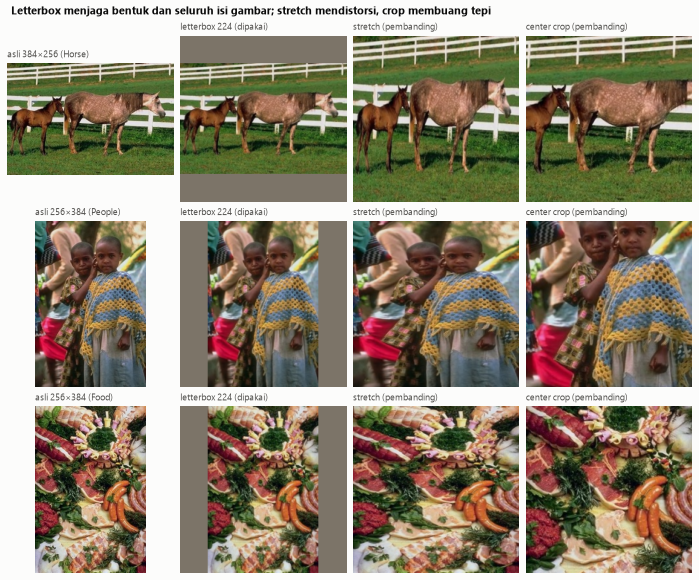

In [10]:
def stretch(path):
    with Image.open(path) as im:
        return im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), RESAMPLE)


def center_crop(path):
    with Image.open(path) as im:
        im = im.convert('RGB')
        s = min(im.size)
        left, top = (im.width - s) // 2, (im.height - s) // 2
        return im.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), RESAMPLE)


is_train = df['split'] == 'train'
examples = pd.concat([df[is_train & (df['orientation'] == o) & (df['class'] == c)].head(1)
                      for o, c in (('landscape', 'Horse'), ('portrait', 'People'), ('portrait', 'Food'))])
fig, axes = plt.subplots(len(examples), 4, figsize=(9.6, 2.65 * len(examples)), layout='constrained')
for row, (_, r) in zip(axes, examples.iterrows()):
    with Image.open(r['path']) as im:
        row[0].imshow(im.convert('RGB'))
    row[1].imshow(X['train'][IDS['train'] == r['code']][0])
    row[2].imshow(stretch(r['path']))
    row[3].imshow(center_crop(r['path']))
    titles = (f"asli {r['width']}×{r['height']} ({r['class']})", 'letterbox 224 (dipakai)', 'stretch (pembanding)', 'center crop (pembanding)')
    for ax, title in zip(row, titles):
        ax.set_title(title, fontsize=9, loc='left', fontweight='normal', color=INK2)
        ax.axis('off')
suptitle(fig, 'Letterbox menjaga bentuk dan seluruh isi gambar; stretch mendistorsi, crop membuang tepi')
save(fig, '06_letterbox_vs_pembanding.png')
plt.show()

**Bacaan.** Stretch tidak membuang isi, tetapi bentuk objek terdistorsi 1,5 kali. Center crop menjaga bentuk, tetapi sepertiga sisi panjang foto terbuang. Letterbox menjaga bentuk dan seluruh isi gambar, dengan konsekuensi sebagian kanvas berisi pita padding dan objek tampil lebih kecil.

disimpan: figures/07_sampel_per_kelas_224.png


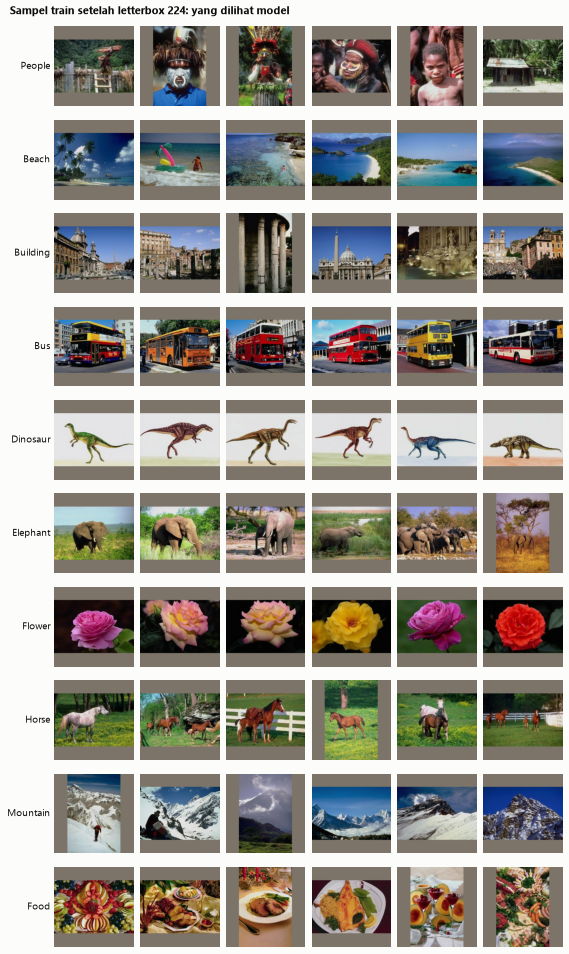

In [11]:
rng = np.random.default_rng(SEED)
per_row = 6
y_train = df.loc[df['split'] == 'train', 'label'].to_numpy()
fig, axes = plt.subplots(len(CLASSES), per_row, figsize=(per_row * 1.3, len(CLASSES) * 1.32), layout='constrained')
for c, name in enumerate(CLASSES):
    idx = rng.choice(np.flatnonzero(y_train == c), per_row, replace=False)
    for k, ax in enumerate(axes[c]):
        ax.imshow(X['train'][idx[k]])
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
    axes[c, 0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=10, color=INK)
suptitle(fig, 'Sampel train setelah letterbox 224: yang dilihat model')
save(fig, '07_sampel_per_kelas_224.png')
plt.show()

**Labeling review.** Setiap baris berisi gambar yang sesuai dengan nama kelasnya, jadi aturan `label = nomor // 100` konsisten dengan isi gambar.

## 7. Padding setelah penerjemah input tiap model

Data masuk ke model dalam rentang 0–255, lalu setiap model memakai penerjemah input resminya di dalam model. Warna padding sama dengan rata-rata piksel ImageNet, jadi setelah penerjemah nilainya mendekati nol dan tidak membentuk nilai ekstrem.

In [12]:
IMAGENET_MEAN, IMAGENET_STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
pad = np.array(PAD_RGB, dtype=np.float64)
display(pd.DataFrame({
    'model': ['ConvNeXtTiny, EfficientNetV2B0, DenseNet121', 'MobileNetV3Large, ResNet50V2'],
    'penerjemah': ['normalisasi mean/std ImageNet', 'x/127,5 − 1'],
    'nilai padding (R, G, B)': [np.round((pad / 255 - IMAGENET_MEAN) / IMAGENET_STD, 3).tolist(), np.round(pad / 127.5 - 1, 3).tolist()],
}))
print('Parameter augmentation (hanya train, lewat du.get_augmentation()):')
display(pd.DataFrame({
    'parameter': ['flip', 'rotasi', 'zoom', 'translasi', 'brightness', 'contrast', 'pengisi area kosong'],
    'nilai': [du.FLIP, f'±{du.ROTASI_DERAJAT}°', f'zoom in hingga {abs(du.ZOOM[0]):.0%}', f'±{du.TRANSLASI:.0%}',
              f'±{du.BRIGHTNESS:.0%}', f'±{du.CONTRAST:.0%}', du.FILL_MODE],
}))

,model,penerjemah,"nilai padding (R, G, B)"
0,"ConvNeXtTiny, EfficientNetV2B0, DenseNet121",normalisasi mean/std ImageNet,"[0.006, -0.005, 0.008]"
1,"MobileNetV3Large, ResNet50V2","x/127,5 − 1","[-0.027, -0.09, -0.184]"


Parameter augmentation (hanya train, lewat du.get_augmentation()):


,parameter,nilai
0,flip,horizontal
1,rotasi,±15°
2,zoom,zoom in hingga 20%
3,translasi,±5%
4,brightness,±15%
5,contrast,±15%
6,pengisi area kosong,reflect


## 8. Ringkasan untuk slide

In [13]:
ringkasan = {
    'sidik_data_utils': du.sidik_config(cetak=False)[:12],
    'jumlah_gambar': {s: int(split_counts[s]) for s in SPLITS},
    'ukuran_asli': {f'{w}x{h}': int(n) for w, h, n in size_tab[['width', 'height', 'jumlah']].itertuples(index=False)},
    'porsi_portrait_persen': round(float((df['orientation'] == 'portrait').mean() * 100), 1),
    'porsi_padding_persen': round(float(pad_share * 100), 1),
    'gambar_ditandai': [{'split': str(r['split']), 'nomor': int(r['code']), 'kelas': str(r['class']), 'tanda': r['flag']}
                        for _, r in flagged.iterrows()],
    'pasangan_foto_mirip': [{'a': r['a'], 'b': r['b'], 'kelas': r['kelas a'], 'mse': round(float(r['mse']), 4)}
                            for _, r in pairs.iterrows()],
    'test_punya_kembaran': test_twins,
}
Path('eda_2.json').write_text(json.dumps(ringkasan, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
print(json.dumps({k: v for k, v in ringkasan.items() if k not in ('gambar_ditandai', 'pasangan_foto_mirip')}, indent=2))
print(f"gambar ditandai: {len(ringkasan['gambar_ditandai'])}, pasangan foto mirip: {len(ringkasan['pasangan_foto_mirip'])}")

{
  "sidik_data_utils": "b3e0629783c5",
  "jumlah_gambar": {
    "train": 500,
    "validation": 300,
    "test": 200
  },
  "ukuran_asli": {
    "256x384": 200,
    "384x256": 800
  },
  "porsi_portrait_persen": 20.0,
  "porsi_padding_persen": 33.5,
  "test_punya_kembaran": [
    786,
    787,
    789,
    791,
    795,
    796
  ]
}
gambar ditandai: 16, pasangan foto mirip: 11


| Slide | Bahan |
|---|---|
| 3 Dataset dan split | `01_distribusi_kelas.png`, `07_sampel_per_kelas_224.png` |
| 4 EDA ukuran dan cahaya | `02_orientasi_portrait.png`, `03_kecerahan_kontras.png`, `04_gambar_ditandai.png` |
| 5 Foto mirip antar-split | `05_kandidat_foto_mirip.png`, daftar `test_punya_kembaran` di `eda_2.json` |
| 6 Pipeline data | `06_letterbox_vs_pembanding.png`, tabel penerjemah di bagian 7 |
| 7 Augmentation | tabel parameter di bagian 7 |